# Exploración AML 2: Sensores de Caudal y Recurrencia de Pares

## 1. Pregunta de Negocio y Objetivos
**Pregunta central:** ¿El ratio continuo de caudal (`ratio_vaciado`) y la recurrencia entre pares origen-destino (`frecuencia_conexion`) aportan señal discriminante frente a la regla de vaciado total (`flag_vaciado = (amount == oldbalanceOrg)`) para detectar operaciones de *layering*?

**Objetivos:**
1. Determinar si los atacantes operan mediante drenado fraccionado o si el patrón en el subconjunto TRANSFER/CASH_OUT de PaySim es estrictamente binario.
2. Evaluar el riesgo analítico de la recurrencia pura frente a casos de control legítimos mediante una simulación sintética aislada.
3. Generar y exportar `paysim_features_v2.parquet` bajo estrictas aserciones de esquema, sin duplicados ni contaminación sintética.

## 2. Carga del Flujo y Purga Preventiva de Columnas
Cargamos la salida procesada del Notebook 1 (`paysim_features.parquet`). Purgamos cualquier columna residual de ejecuciones anteriores y validamos el esquema base.

In [1]:
import pandas as pd
import numpy as np

# 1. Carga de datos base
ruta_origen = '../data/processed/paysim_features.parquet'
df = pd.read_parquet(ruta_origen)

# 2. Purga preventiva de columnas residuales (sin warning de deprecación)
columnas_residuales = [col for col in df.columns if 'frecuencia' in col or col.endswith('_x') or col.endswith('_y')]
if columnas_residuales:
    print(f"Purgando columnas residuales de origen: {columnas_residuales}")
    df = df.drop(columns=columnas_residuales)

# 3. Inspección dimensional y balance de clases
print(f"Dimensiones del dataset limpio: {df.shape[0]:,} filas x {df.shape[1]} columnas")
resumen_clases = pd.DataFrame({
    'Total': df['isFraud'].value_counts(),
    'Porcentaje (%)': (df['isFraud'].value_counts(normalize=True) * 100).round(4)
})
display(resumen_clases)

# 4. Contrato estricto de esquema
columnas_requeridas = ['in_degree', 'out_degree', 'flag_vaciado', 'oldbalanceOrg', 'newbalanceOrig', 'amount', 'nameOrig', 'nameDest']
columnas_faltantes = [col for col in columnas_requeridas if col not in df.columns]

assert len(columnas_faltantes) == 0, f"Error de contrato: Faltan columnas requeridas {columnas_faltantes}"
assert len(df.columns) == len(set(df.columns)), "Error: Existen nombres de columnas duplicados."
print(f"Esquema verificado. Columnas actuales ({len(df.columns)}): {list(df.columns)}")

Purgando columnas residuales de origen: ['frecuencia_transacciones', 'frecuencia_conexion']
Dimensiones del dataset limpio: 2,770,409 filas x 15 columnas


,Total,Porcentaje (%)
isFraud,,
0,2762196,99.7035
1,8213,0.2965


Esquema verificado. Columnas actuales (15): ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'in_degree', 'out_degree', 'flag_vaciado', 'ratio_vaciado']


## 3. Chequeo de Calidad e Integridad Contable
Auditamos la presencia de valores nulos, montos negativos y transacciones donde `amount > oldbalanceOrg`. Cuantificamos la proporción exacta de operaciones legítimas con saldo inicial cero para caracterizar los descalces contables del dataset.

In [2]:
# 1. Chequeo de nulos y negativos
cols_financieras = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
nulos = df[cols_financieras].isnull().sum().to_dict()
negativos = (df[cols_financieras] < 0).sum().to_dict()

print(f"Valores nulos: {nulos}")
print(f"Valores negativos: {negativos}")

# 2. Análisis cuantitativo de amount > oldbalanceOrg
sobregiro_legitimo = df[(df['isFraud'] == 0) & (df['amount'] > df['oldbalanceOrg'])]
sobregiro_fraude = df[(df['isFraud'] == 1) & (df['amount'] > df['oldbalanceOrg'])]

total_fraudes = (df['isFraud'] == 1).sum()
pct_fraude_sobregiro = (len(sobregiro_fraude) / total_fraudes) * 100

# Verificación de saldo cero en legítimas
legitimas_saldo_cero = (sobregiro_legitimo['oldbalanceOrg'] == 0).sum()
pct_saldo_cero = (legitimas_saldo_cero / len(sobregiro_legitimo)) * 100

print(f"\nDiscrepancia amount > oldbalanceOrg:")
print(f"- En fraude: {len(sobregiro_fraude):,} de {total_fraudes:,} transacciones ({pct_fraude_sobregiro:.2f}%)")
print(f"- En legítimo: {len(sobregiro_legitimo):,} transacciones")
print(f"  └ De las cuales oldbalanceOrg == 0: {legitimas_saldo_cero:,} ({pct_saldo_cero:.2f}%)")

Valores nulos: {'amount': 0, 'oldbalanceOrg': 0, 'newbalanceOrig': 0, 'oldbalanceDest': 0, 'newbalanceDest': 0}
Valores negativos: {'amount': 0, 'oldbalanceOrg': 0, 'newbalanceOrig': 0, 'oldbalanceDest': 0, 'newbalanceDest': 0}

Discrepancia amount > oldbalanceOrg:
- En fraude: 29 de 8,213 transacciones (0.35%)
- En legítimo: 2,488,605 transacciones
  └ De las cuales oldbalanceOrg == 0: 1,308,541 (52.58%)


### Hallazgos de Integridad Contable
- **Nulos y negativos:** Inexistentes en los atributos contables analizados.
- **Discrepancia `amount > oldbalanceOrg`:**
  - En fraude se registra en 29 transacciones (0.35%), atribuibles posiblemente a sobregiros forzados o artefactos en la generación sintética de los agentes de ataque.
  - En transacciones legítimas (2,488,605 casos), el 52.58% (1,308,541 registros) se origina en cuentas con saldo inicial exactamente igual a cero (`oldbalanceOrg == 0`), operando como canales de recepción o dispersión sin fondos retenidos.

## 4. Sensor de Caudal: Ratio de Vaciado
Calculamos la proporción de fondos transferidos respecto al saldo inicial disponible (`amount / oldbalanceOrg`). Protegemos la operación frente a divisiones por cero mediante `np.where` y analizamos la distribución estadística para evaluar si los atacantes implementan drenados parciales.

In [3]:
# 1. Cálculo idempotente del ratio de vaciado
df['ratio_vaciado'] = np.where(
    df['oldbalanceOrg'] > 0,
    df['amount'] / df['oldbalanceOrg'],
    0.0
)

# 2. Resumen estadístico por percentiles
dist_legitimo = df[df['isFraud'] == 0]['ratio_vaciado'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(4)
dist_fraude = df[df['isFraud'] == 1]['ratio_vaciado'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(4)

resumen_caudal = pd.DataFrame({'Legítimo (0)': dist_legitimo, 'Fraude (1)': dist_fraude})
print("Distribución estadística del ratio de vaciado:")
display(resumen_caudal)

# 3. Partición matemática exacta de los fraudes (8,213 casos)
fraudes_totales = (df['isFraud'] == 1).sum()
fraudes_vaciado_exacto = ((df['isFraud'] == 1) & (df['flag_vaciado'] == 1)).sum()
fraudes_restantes = df[(df['isFraud'] == 1) & (df['flag_vaciado'] == 0)]

casos_parciales = fraudes_restantes[(fraudes_restantes['ratio_vaciado'] > 0) & (fraudes_restantes['ratio_vaciado'] < 1)]
casos_sobregiro = fraudes_restantes[fraudes_restantes['amount'] > fraudes_restantes['oldbalanceOrg']]
sobregiro_saldo_cero = casos_sobregiro[casos_sobregiro['oldbalanceOrg'] == 0]

print(f"\nPartición matemática de los {fraudes_totales:,} fraudes:")
print(f"1. Vaciado exacto (amount == oldbalanceOrg): {fraudes_vaciado_exacto:,} ({fraudes_vaciado_exacto / fraudes_totales * 100:.2f}%)")
print(f"2. Fraudes restantes sin vaciado exacto:     {len(fraudes_restantes):,} ({len(fraudes_restantes) / fraudes_totales * 100:.2f}%)")
print(f"   ├─ Vaciado parcial estricto (0 < ratio < 1): {len(casos_parciales)} ({len(casos_parciales) / fraudes_totales * 100:.2f}%)")
print(f"   └─ Sobregiro (ratio > 1):                   {len(casos_sobregiro)} ({len(casos_sobregiro) / fraudes_totales * 100:.2f}%)")
print(f"      └─ De los cuales inician con saldo cero:  {len(sobregiro_saldo_cero)}")

# Verificación de suma cerrada
assert len(casos_parciales) + len(casos_sobregiro) == len(fraudes_restantes) == 179

# 4. Caracterización de los 150 casos con vaciado parcial estricto
print("\nCaracterización de los 150 casos de vaciado parcial estricto:")
print(f"- Cuentas origen únicas:    {casos_parciales['nameOrig'].nunique()}")
print(f"- Cuentas destino únicas:   {casos_parciales['nameDest'].nunique()}")
print(f"- Tipos de transacción:     {casos_parciales['type'].value_counts().to_dict()}")
print(f"- Monto mediano:            ${casos_parciales['amount'].median():,.2f}")
print(f"- Saldo origen mediano:     ${casos_parciales['oldbalanceOrg'].median():,.2f}")
print(f"- Ratio vaciado mediano:    {casos_parciales['ratio_vaciado'].median():.4f}")
print(f"- Rango del ratio:          [{casos_parciales['ratio_vaciado'].min():.4f}, {casos_parciales['ratio_vaciado'].max():.4f}]")

Distribución estadística del ratio de vaciado:


,Legítimo (0),Fraude (1)
count,2.762196e+06,8213.0000
mean,1.459728e+02,0.9938
std,4.967900e+03,0.3908
min,0.000000e+00,0.0000
10%,0.000000e+00,1.0000
25%,0.000000e+00,1.0000
50%,2.203000e-01,1.0000
75%,6.540400e+00,1.0000
90%,4.091790e+01,1.0000
99%,1.944447e+03,1.0000



Partición matemática de los 8,213 fraudes:
1. Vaciado exacto (amount == oldbalanceOrg): 8,034 (97.82%)
2. Fraudes restantes sin vaciado exacto:     179 (2.18%)
   ├─ Vaciado parcial estricto (0 < ratio < 1): 150 (1.83%)
   └─ Sobregiro (ratio > 1):                   29 (0.35%)
      └─ De los cuales inician con saldo cero:  25

Caracterización de los 150 casos de vaciado parcial estricto:
- Cuentas origen únicas:    150
- Cuentas destino únicas:   150
- Tipos de transacción:     {'TRANSFER': 149, 'CASH_OUT': 1}
- Monto mediano:            $10,000,000.00
- Saldo origen mediano:     $16,359,677.71
- Ratio vaciado mediano:    0.6049
- Rango del ratio:          [0.0384, 0.9827]


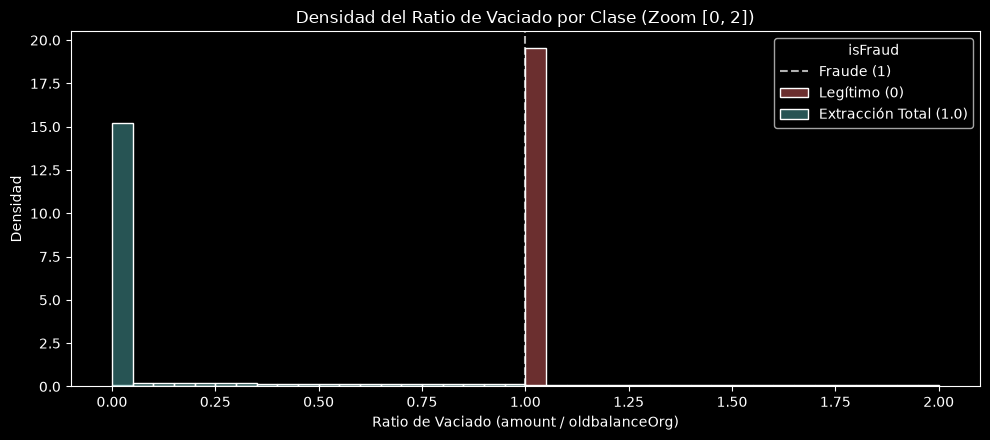

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 4.5))

# Visualización de la densidad acotada en [0, 2] para inspeccionar la masa crítica
sns.histplot(
    data=df[df['ratio_vaciado'] <= 2],
    x='ratio_vaciado',
    hue='isFraud',
    bins=40,
    stat='density',
    common_norm=False,
    palette=['#4fa8a8', '#d65f5f'],
    ax=ax
)

ax.set_title('Densidad del Ratio de Vaciado por Clase (Zoom [0, 2])')
ax.set_xlabel('Ratio de Vaciado (amount / oldbalanceOrg)')
ax.set_ylabel('Densidad')
ax.axvline(1.0, color='white', linestyle='--', alpha=0.7, label='Extracción Total (1.0)')
ax.legend(title='isFraud', labels=['Fraude (1)', 'Legítimo (0)', 'Extracción Total (1.0)'])

plt.tight_layout()
plt.show()

### Conclusiones del Sensor de Caudal
1. **Comportamiento en Fraude:** El 97.82% de las transacciones fraudulentas vacían la totalidad de los fondos mediante extracción exacta (`amount == oldbalanceOrg`). Los 179 casos restantes componen una partición disjunta cerrada:
   - **150 transacciones (1.83%):** Drenado parcial estricto ($0 < \text{ratio} < 1$). Corresponden a 150 pares únicos donde el 99.3% (149) son transferencias que alcanzaron el límite superior de transferencia ($10,000,000.00) sobre cuentas con saldo mediano de $16.36M (ratio mediano de 0.6049). No refleja fragmentación deliberada, sino restricción por límite transaccional.
   - **29 transacciones (0.35%):** Sobregiro (`amount > oldbalanceOrg`), donde 25 casos inician con saldo cero (`oldbalanceOrg == 0`).
2. **Dispersión en Tráfico Legítimo:** Presenta una mediana de 0.22 con amplia asimetría en la cola superior (percentil 75 en 6.54 y valores extremos elevados), generado por transacciones con saldos de origen cercanos a cero.
3. **Decisión Metodológica:** `ratio_vaciado` se mantiene como variable continua para parametrizar tanto las extracciones completas como aquellas truncadas por el límite de diez millones, complementando al indicador binario `flag_vaciado`.

## 5. Sensor de Recurrencia en Datos Reales
En tipologías de *layering*, los pares origen-destino suelen registrar operaciones reiteradas en el tiempo. Calculamos `frecuencia_conexion` como el conteo de transacciones por par `(nameOrig, nameDest)` mediante agrupación directa e idempotente.

In [5]:
# 1. Asignación directa e idempotente de frecuencia de pares origen-destino
df['frecuencia_conexion'] = df.groupby(['nameOrig', 'nameDest'])['step'].transform('size')

# 2. Distribución estadística por clase
resumen_recurrencia = df.groupby('isFraud')['frecuencia_conexion'].agg(['count', 'min', 'mean', 'max'])
print("Estadísticas de frecuencia_conexion en datos reales:")
display(resumen_recurrencia)

# 3. Verificación de conexiones con frecuencia > 1
repetidos_legitimos = ((df['isFraud'] == 0) & (df['frecuencia_conexion'] > 1)).sum()
repetidos_fraude = ((df['isFraud'] == 1) & (df['frecuencia_conexion'] > 1)).sum()

print(f"\nTransacciones con frecuencia_conexion > 1:")
print(f"- Operaciones legítimas repetidas: {repetidos_legitimos}")
print(f"- Operaciones de fraude repetidas:   {repetidos_fraude}")

Estadísticas de frecuencia_conexion en datos reales:


,count,min,mean,max
isFraud,,,,
0,2762196,1,1.0,1
1,8213,1,1.0,1



Transacciones con frecuencia_conexion > 1:
- Operaciones legítimas repetidas: 0
- Operaciones de fraude repetidas:   0


### Hallazgos de Recurrencia en el Subconjunto Analizado
- **Distribución en el conjunto analizado:** En las 2,770,409 transacciones analizadas (`TRANSFER` y `CASH_OUT`), la variable `frecuencia_conexion` es estrictamente igual a 1; ningún par origen-destino registra operaciones reiteradas en este conjunto.
- **Implicancia metodológica:** Dada la ausencia de varianza empírica en estos datos, la evaluación de la recurrencia se realiza de forma analítica en un entorno sintético controlado y aislado.

## 6. Validación Conceptual con Casos Controlados (Entorno Aislado)
Dado que los pares en este subconjunto no se repiten, construimos un entorno de prueba sobre una copia temporal (`df_sim`).

Diseñamos dos escenarios para medir la respuesta del sensor:
1. **Caso Mula (*Layering* fraudulento):** 5 transferencias repetidas con vaciado total de fondos por transacción (`amount = 1000`, `oldbalanceOrg = 1000`, `newbalanceOrig = 0`).
2. **Caso Nómina (Control legítimo recurrente):** 5 transferencias repetidas periódicas sin vaciar la cuenta (`amount = 1500`, `oldbalanceOrg = 10000`, `newbalanceOrig = 8500`), resultando en un `ratio_vaciado = 0.15`.

*Regla de integridad:* Los datos de prueba solo existen en `df_sim`. Todas las métricas derivadas (`flag_vaciado`, `ratio_vaciado`, `frecuencia_conexion`) se calculan mediante fórmulas dinámicas idénticas a las del pipeline de producción.

In [6]:
# 1. Copia aislada para validación conceptual
df_sim = df.copy()

# 2. Transacciones de prueba con datos crudos (sin variables derivadas escritas a mano)
mula_sintetica = pd.DataFrame([{
    'step': step,
    'type': 'TRANSFER',
    'amount': 1000.0,
    'nameOrig': "C_MULA_TEST",
    'oldbalanceOrg': 1000.0,
    'newbalanceOrig': 0.0,
    'nameDest': "C_ESTANQUE_TEST",
    'oldbalanceDest': 0.0,
    'newbalanceDest': 1000.0,
    'isFraud': 1,
    'isFlaggedFraud': 0
} for step in range(1, 6)])

nomina_sintetica = pd.DataFrame([{
    'step': step,
    'type': 'TRANSFER',
    'amount': 1500.0,
    'nameOrig': "C_EMPRESA_TEST",
    'oldbalanceOrg': 10000.0,
    'newbalanceOrig': 8500.0,
    'nameDest': "C_EMPLEADO_TEST",
    'oldbalanceDest': 500.0,
    'newbalanceDest': 2000.0,
    'isFraud': 0,
    'isFlaggedFraud': 0
} for step in range(1, 6)])

# 3. Inyección en DataFrame aislado
df_sim = pd.concat([df_sim, mula_sintetica, nomina_sintetica], ignore_index=True)

# 4. Cálculo dinámico con fórmulas idénticas a producción
df_sim['flag_vaciado'] = np.where(df_sim['amount'] == df_sim['oldbalanceOrg'], 1, 0)
df_sim['ratio_vaciado'] = np.where(df_sim['oldbalanceOrg'] > 0, df_sim['amount'] / df_sim['oldbalanceOrg'], 0.0)
df_sim['frecuencia_conexion'] = df_sim.groupby(['nameOrig', 'nameDest'])['step'].transform('size')

# 5. Evaluación de respuesta de sensores ante los casos de control
casos_control = df_sim[df_sim['nameOrig'].isin(["C_MULA_TEST", "C_EMPRESA_TEST"])]
resumen_control = casos_control.groupby(['nameOrig', 'isFraud']).agg({
    'frecuencia_conexion': 'max',
    'flag_vaciado': 'max',
    'ratio_vaciado': 'mean',
    'amount': 'count'
}).rename(columns={'amount': 'total_transacciones'}).reset_index()

print("Respuesta de Sensores Derivados Dinámicamente:")
display(resumen_control)

Respuesta de Sensores Derivados Dinámicamente:


,nameOrig,isFraud,frecuencia_conexion,flag_vaciado,ratio_vaciado,total_transacciones
0,C_EMPRESA_TEST,0,5,0,0.15,5
1,C_MULA_TEST,1,5,1,1.00,5


### Hallazgos de la Validación Controlada
- **Ambigüedad de la recurrencia univariada:** Ambos escenarios exhiben exactamente el mismo nivel de repetición (`frecuencia_conexion = 5`). Una regla de corte basada exclusivamente en repetición de pares clasificaría erróneamente transferencias de nómina como sospechosas al no considerar el contexto contable.
- **Poder discriminante compuesto:** La señal de detección se obtiene al cruzar la recurrencia con los sensores de saldo:
  - **Mula:** `frecuencia = 5`, `ratio_vaciado = 1.00`, `flag_vaciado = 1`.
  - **Nómina:** `frecuencia = 5`, `ratio_vaciado = 0.15`, `flag_vaciado = 0`.
- **Criterio metodológico:** La variable `frecuencia_conexion` se mantiene en el pipeline para habilitar el aprendizaje de relaciones no lineales en modelos multivariables (XGBoost), pero no constituye una regla heurística suficiente por sí sola.

## 7. Panel de Control y Análisis de Señales Topológicas y Contables
Calculamos formalmente las medianas de concentración de entrada (`in_degree`) por clase e integramos un panel comparativo de tres dimensiones: vaciado binario (`amount == oldbalanceOrg`), concentración topológica y densidad continua del ratio de vaciado.

Mediana de in_degree por clase:
- Tráfico legítimo (isFraud = 0): 9.0
- Tráfico de fraude (isFraud = 1):  3.0


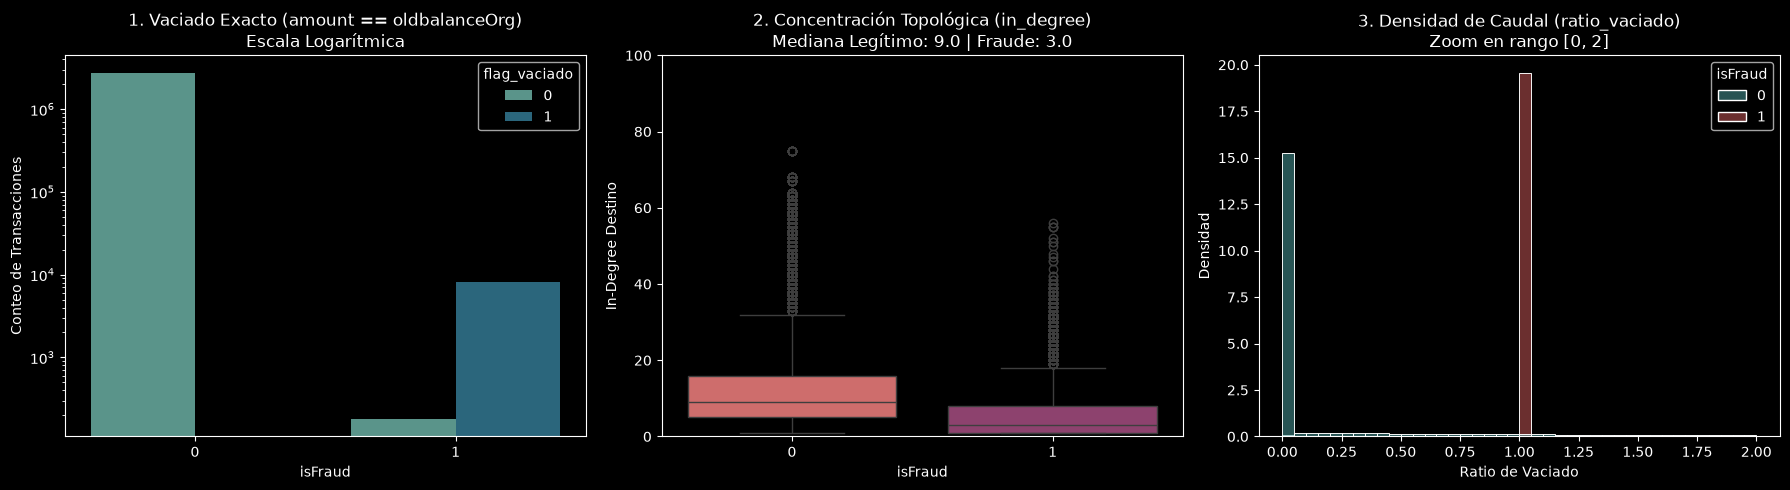

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Medición cuantitativa explícita de in_degree
medianas_in_degree = df.groupby('isFraud')['in_degree'].median()
print("Mediana de in_degree por clase:")
print(f"- Tráfico legítimo (isFraud = 0): {medianas_in_degree[0]:.1f}")
print(f"- Tráfico de fraude (isFraud = 1):  {medianas_in_degree[1]:.1f}")

# 2. Configuración y renderizado del panel de control
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Vaciado Absoluto
sns.countplot(
    data=df, 
    x='isFraud', 
    hue='flag_vaciado', 
    ax=axes[0], 
    palette='crest'
)
axes[0].set_yscale('log')
axes[0].set_title('1. Vaciado Exacto (amount == oldbalanceOrg)\nEscala Logarítmica')
axes[0].set_xlabel('isFraud')
axes[0].set_ylabel('Conteo de Transacciones')

# Gráfico 2: Concentración Topológica de Destino
sns.boxplot(
    data=df, 
    x='isFraud', 
    y='in_degree', 
    hue='isFraud', 
    legend=False, 
    ax=axes[1], 
    palette='flare'
)
axes[1].set_ylim(0, 100)
axes[1].set_title(f'2. Concentración Topológica (in_degree)\nMediana Legítimo: {medianas_in_degree[0]:.1f} | Fraude: {medianas_in_degree[1]:.1f}')
axes[1].set_xlabel('isFraud')
axes[1].set_ylabel('In-Degree Destino')

# Gráfico 3: Densidad de Caudal Continuo
sns.histplot(
    data=df[df['ratio_vaciado'] <= 2], 
    x='ratio_vaciado', 
    hue='isFraud', 
    bins=40, 
    stat='density', 
    common_norm=False, 
    palette=['#4fa8a8', '#d65f5f'], 
    ax=axes[2]
)
axes[2].set_title('3. Densidad de Caudal (ratio_vaciado)\nZoom en rango [0, 2]')
axes[2].set_xlabel('Ratio de Vaciado')
axes[2].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

### Lectura del Panel de Control
- **Vaciado Exacto (Gráfico 1):** El 97.82% de las transacciones de fraude extraen exactamente el saldo inicial disponible (`amount == oldbalanceOrg`), frente a una proporción marginal en operaciones legítimas.
- **Concentración Topológica (Gráfico 2):** Como dato descriptivo de la muestra analizada, las cuentas destino de fraude exhiben una mediana de conexiones de entrada (`in_degree`) de 3.0 frente a 9.0 en operaciones legítimas.
- **Densidad del Ratio de Vaciado (Gráfico 3):** La distribución empírica en fraude se concentra marcadamente en el valor 1.0, evidenciando la dominancia de extracciones completas frente a operaciones de volumen variable.

## 8. Conclusiones de la Exploración de Sensores

1. **Sensor de Caudal (`ratio_vaciado`):** El 97.82% de los fraudes drenan exactamente el saldo disponible (`amount == oldbalanceOrg`). La partición matemática de los 179 casos restantes comprende 150 operaciones (1.83%) truncadas por el límite operativo de $10,000,000.00 sobre cuentas con saldos mayores, y 29 operaciones (0.35%) con sobregiro, de las cuales 25 inician con saldo cero. Se conserva la variable continua para capturar esta dinámica de volumen.
2. **Sensor de Recurrencia (`frecuencia_conexion`):** En el subconjunto `TRANSFER` y `CASH_OUT`, ningún par registra repetición (`frecuencia_conexion = 1`). La prueba en `df_sim` demostró que la recurrencia por sí sola es ambigua, requiriendo el cruce con variables de saldo y topología.
3. **Integridad y Descalces Contables:** Se registraron 29 operaciones de fraude donde `amount > oldbalanceOrg`. En operaciones legítimas, el 52.58% de las transacciones con `amount > oldbalanceOrg` se originan en cuentas que inician con saldo cero (`oldbalanceOrg == 0`).

## 9. Sellado y Exportación de la Tubería (V2)
Exportamos el dataset resultante a un archivo nuevo (`paysim_features_v2.parquet`) sin sobreescribir la entrada original. Realizamos aserciones de control para verificar dimensiones, unicidad de columnas, ausencia de residuos y ausencia estricta de cuentas de prueba sintéticas.

In [8]:
# 1. Definición de ruta destino
ruta_destino = '../data/processed/paysim_features_v2.parquet'

# 2. Aserción de dimensiones
filas_esperadas = 2770409
assert len(df) == filas_esperadas, f"Error: Filas incorrectas ({len(df):,} vs {filas_esperadas:,})"

# 3. Aserción de ausencia de contaminación sintética
assert 'C_MULA_TEST' not in df['nameOrig'].values, "Error crítico: C_MULA_TEST detectada en datos finales."
assert 'C_EMPRESA_TEST' not in df['nameOrig'].values, "Error crítico: C_EMPRESA_TEST detectada en datos finales."

# 4. Aserción de esquema limpio (sin duplicados ni residuos)
assert len(df.columns) == len(set(df.columns)), "Error: Existen nombres de columnas duplicados."
columnas_residuales = [col for col in df.columns if col.endswith('_x') or col.endswith('_y') or col == 'frecuencia_transacciones']
assert len(columnas_residuales) == 0, f"Error: Columnas residuales detectadas: {columnas_residuales}"

# 5. Exportación
df.to_parquet(ruta_destino, index=False)

print(f"Exportación exitosa y auditada a: {ruta_destino}")
print(f"Total registros exportados: {len(df):,}")
print(f"Columnas finales ({len(df.columns)}): {list(df.columns)}")

Exportación exitosa y auditada a: ../data/processed/paysim_features_v2.parquet
Total registros exportados: 2,770,409
Columnas finales (16): ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'in_degree', 'out_degree', 'flag_vaciado', 'ratio_vaciado', 'frecuencia_conexion']
